# **Baseline models**

1. Ridge regression;
2. histogram gradient boosting;
3. Neural Network (light/basic)

In [1]:
from pathlib import Path
import random
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

random_state = 42

EXPECTED_LABELLED_PLANETS = 41423
EXPECTED_SPECTRAL_CHANNELS = 52
EXPECTED_FEATURE_COUNT = 111
EXPECTED_SPLIT_COUNTS = {
    "train": 24853,
    "validation": 4142,
    "calibration": 6214,
    "test": 6214
}

SPECTRUM_FEATURES = [f"spectrum_{channel:02d}" for channel in range(EXPECTED_SPECTRAL_CHANNELS)]

NOISE_FEATURES = [f"noise_{channel:02d}" for channel in range(EXPECTED_SPECTRAL_CHANNELS)]

METADATA_FEATURES = [
    "star_distance",
    "star_mass_kg",
    "star_radius_m",
    "star_temperature",
    "planet_mass_kg",
    "planet_orbital_period",
    "planet_distance",
]

TARGET_COLUMNS = [
    "planet_radius",
    "planet_temp",
    "log_H2O",
    "log_CO2",
    "log_CO",
    "log_CH4",
    "log_NH3",
]

FEATURE_COLUMNS = [
    *SPECTRUM_FEATURES,
    *NOISE_FEATURES,
    *METADATA_FEATURES
]

SPECTRAL_PATH = (
    PROJECT_ROOT
    / "FullDataset"
    / "TrainingData"
    / "SpectralData.hdf5"
)

AUXILIARY_PATH = (
    PROJECT_ROOT
    / "FullDataset"
    / "TrainingData"
    / "AuxillaryTable.csv"
)

TARGET_PATH = (
    PROJECT_ROOT
    / "FullDataset"
    / "TrainingData"
    / "Ground Truth Package"
    / "FM_Parameter_Table.csv"
)

SPLIT_ASSIGNMENT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "split_assignments_data.csv"
)

if len(FEATURE_COLUMNS) != EXPECTED_FEATURE_COUNT:
    raise ValueError(
        f"Expected {EXPECTED_FEATURE_COUNT} features, "
        f"defined {len(FEATURE_COLUMNS)}."
    )

for required_path in [
    SPECTRAL_PATH,
    AUXILIARY_PATH,
    TARGET_PATH
]:
    if not required_path.is_file():
        raise FileNotFoundError(f"Required source file not found: {required_path}")

print("Project root:", PROJECT_ROOT)
print("Feature count:", len(FEATURE_COLUMNS))
print("Target count:", len(TARGET_COLUMNS))

Project root: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction
Feature count: 111
Target count: 7


### **Load the data**

In [3]:
metadata_source = pd.read_csv(AUXILIARY_PATH, dtype={"planet_ID": "string"})
target_source = pd.read_csv(TARGET_PATH, dtype={"planet_ID": "string"})

if set(metadata_source["planet_ID"]) != set(target_source["planet_ID"]):
    raise ValueError("Metadata and target planet IDs do not match.")

labelled_table = metadata_source[["planet_ID", *METADATA_FEATURES]].merge(
    target_source[["planet_ID", *TARGET_COLUMNS]],
    on="planet_ID",
    how="inner",
    validate="one_to_one"
)

if len(labelled_table) != EXPECTED_LABELLED_PLANETS:
    raise ValueError(
        f"Expected {EXPECTED_LABELLED_PLANETS} labelled planets, "
        f"found {len(labelled_table)}."
    )

print("Aligned labelled rows:", len(labelled_table))

Aligned labelled rows: 41423


### **Split the data**

In [4]:
if not SPLIT_ASSIGNMENT_PATH.is_file():
    raise FileNotFoundError(
        f"Split assignment not found: {SPLIT_ASSIGNMENT_PATH}. "
        "Run notebooks/03_data_pipeline.ipynb first."
    )

split_assignment = pd.read_csv(
    SPLIT_ASSIGNMENT_PATH,
    dtype={"planet_ID": "string", "split": "string"},
)

required_columns = {"planet_ID", "split"}
if not required_columns.issubset(split_assignment.columns):
    raise ValueError("Split assignment must contain planet_ID and split columns.")

split_assignment = (
    split_assignment[["planet_ID", "split"]]
    .sort_values("planet_ID", kind="stable")
    .reset_index(drop=True)
)

if not split_assignment["planet_ID"].is_unique:
    raise ValueError("Split assignment contains duplicate planet IDs.")

if set(split_assignment["planet_ID"]) != set(labelled_table["planet_ID"]):
    raise ValueError("Split assignment IDs do not match the labelled data.")

if set(split_assignment["split"]) != set(EXPECTED_SPLIT_COUNTS):
    raise ValueError("Split assignment contains unexpected partition labels.")

actual_split_counts = (
    split_assignment["split"]
    .value_counts()
    .reindex(EXPECTED_SPLIT_COUNTS, fill_value=0)
    .astype(int)
)

if actual_split_counts.to_dict() != EXPECTED_SPLIT_COUNTS:
    raise ValueError(f"Unexpected split counts: {actual_split_counts.to_dict()}")

split_summary = pd.DataFrame({
    "n_planets": actual_split_counts,
    "fraction": actual_split_counts / EXPECTED_LABELLED_PLANETS})

display(split_summary)

,n_planets,fraction
split,,
train,24853,0.599981
validation,4142,0.099993
calibration,6214,0.150013
test,6214,0.150013


### **Development data**

i.e. training + validation data partitions

In [5]:
development_assignment = split_assignment.loc[split_assignment["split"].isin(["train", "validation"])].copy()
development_ids = development_assignment["planet_ID"].astype(str).tolist()

spectrum_values = np.empty((len(development_ids), EXPECTED_SPECTRAL_CHANNELS), dtype=np.float64)
noise_values = np.empty_like(spectrum_values)

with h5py.File(SPECTRAL_PATH, "r") as spectral_file:
    for row_index, planet_id in enumerate(development_ids):
        planet_group = spectral_file[f"Planet_{planet_id}"]
        spectrum_values[row_index] = planet_group["instrument_spectrum"][()]
        noise_values[row_index] = planet_group["instrument_noise"][()]

expected_spectral_shape = (EXPECTED_SPLIT_COUNTS["train"] + EXPECTED_SPLIT_COUNTS["validation"], EXPECTED_SPECTRAL_CHANNELS)
if spectrum_values.shape != expected_spectral_shape or noise_values.shape != expected_spectral_shape:
    raise ValueError("Unexpected assembled spectrum or noise shape.")

print("Development spectra:", spectrum_values.shape)
print("Development noise:", noise_values.shape)

Development spectra: (28995, 52)
Development noise: (28995, 52)


### **Create train and validation X and y sets**

In [6]:
labelled_by_id = labelled_table.set_index("planet_ID")
development_table = labelled_by_id.loc[development_ids]

metadata_values = development_table[METADATA_FEATURES].to_numpy(dtype=np.float64)
development_features = np.column_stack([
    spectrum_values,
    noise_values,
    metadata_values
])

X_development = pd.DataFrame(
    development_features,
    index=development_table.index,
    columns=FEATURE_COLUMNS
)
y_development = development_table[TARGET_COLUMNS].copy()

if X_development.shape != (len(development_ids), EXPECTED_FEATURE_COUNT):
    raise ValueError(f"Unexpected assembled feature shape: {X_development.shape}")

ids_train = split_assignment.loc[split_assignment["split"].eq("train"), "planet_ID"].to_numpy()
ids_validation = split_assignment.loc[split_assignment["split"].eq("validation"), "planet_ID"].to_numpy()

X_train = X_development.loc[ids_train].copy()
X_val = X_development.loc[ids_validation].copy()
y_train = y_development.loc[ids_train].copy()
y_val = y_development.loc[ids_validation].copy()

actual_shapes = {
    "X_train": X_train.shape,
    "X_validation": X_val.shape,
    "y_train": y_train.shape,
    "y_validation": y_val.shape,
}
expected_shapes = {
    "X_train": (EXPECTED_SPLIT_COUNTS["train"], EXPECTED_FEATURE_COUNT),
    "X_validation": (EXPECTED_SPLIT_COUNTS["validation"], EXPECTED_FEATURE_COUNT),
    "y_train": (EXPECTED_SPLIT_COUNTS["train"], len(TARGET_COLUMNS)),
    "y_validation": (EXPECTED_SPLIT_COUNTS["validation"], len(TARGET_COLUMNS)),
}

if actual_shapes != expected_shapes:
    raise ValueError(f"Unexpected train/validation shapes: {actual_shapes}")

if not X_train.index.equals(y_train.index) or not X_val.index.equals(y_val.index):
    raise ValueError("Feature and target rows are misaligned.")

if X_train.columns.tolist() != FEATURE_COLUMNS or y_train.columns.tolist() != TARGET_COLUMNS:
    raise ValueError("Feature or target column order has changed.")

for name, shape in actual_shapes.items():
    print(f"{name}: {shape}")

X_train: (24853, 111)
X_validation: (4142, 111)
y_train: (24853, 7)
y_validation: (4142, 7)


### **Metrics**

In [7]:
def regression_metrics(y_true, y_pred) -> dict[str, float]:

    true_values = np.asarray(y_true, dtype=np.float64).reshape(-1)  # Flatten into a 1D vector
    predicted_values = np.asarray(y_pred, dtype=np.float64).reshape(-1)

    if true_values.shape != predicted_values.shape:
        raise ValueError(f"Target and predicted shapes are different: {true_values.shape} and {predicted_values.shape}")

    if not np.isfinite(true_values).all():
        raise ValueError("Targets contains NaNs or infinite values")

    if not np.isfinite(predicted_values).all():
        raise ValueError("Predictions contain NaNs or infinite values")

    return {"validation_MAE": float(mean_absolute_error(true_values, predicted_values)),
            "validation_RMSE": float(root_mean_squared_error(true_values, predicted_values)),
            "validation_R2": float(r2_score(true_values, predicted_values))}

### **Ridge regression**

This is the simple linear baseline.

Each 'candidate' is a pipeline: `StandardScaler` -> `Ridge`.

`fit` onto `X_train` fits the scaler and Ridge coefficients (alphas).

Validation data is passed to `predict`.

The lowest validation RMSE selects the preferred Ridge configuration.

In [8]:
ridge_alphas = (0.1, 1.0, 10.0, 100.0)

ridge_candidates = []
ridge_best = []

best_ridge_models = {}
best_ridge_predictions = {}
best_ridge_configs = {}

for target in TARGET_COLUMNS:
    y_train_target = y_train[target].to_numpy(dtype=np.float64)

    y_val_target = y_val[target].to_numpy(np.float64)

    best_rmse = np.inf
    best_model = None
    best_prediction = None
    best_alpha = None
    best_metrics = None

    for alpha in ridge_alphas:
        model = Pipeline(steps=[("scaler", StandardScaler()), ("regressor", Ridge(alpha=alpha))])

        start_time = time.perf_counter()

        model.fit(X_train, y_train_target)
        fit_seconds = time.perf_counter() - start_time

        val_prediction = model.predict(X_val)

        metrics = regression_metrics(y_val_target, val_prediction)

        ridge_candidates.append({
            "target": target,
            "alpha": alpha,
            **metrics,
            "fit_seconds": fit_seconds
        })

        # Storing the best model
        if metrics["validation_RMSE"] < best_rmse:
            best_rmse = metrics["validation_RMSE"]
            best_model = model
            best_prediction = (val_prediction.copy())
            best_alpha = alpha
            best_metrics = metrics.copy()

    best_ridge_models[target] = best_model
    best_ridge_predictions[target] = best_prediction

    best_ridge_configs[target] = {
        "family": "Ridge",
        "alpha": float(best_alpha),
        "scaler": "StandardScaler"
    }

    ridge_best.append({
        "target": target,
        "ridge_validation_MAE": (best_metrics["validation_MAE"]),
        "ridge_validation_RMSE": (best_metrics["validation_RMSE"]),
        "ridge_validation_R2": (best_metrics["validation_R2"]),
        "best_ridge_alpha": best_alpha
    })

ridge_candidates_results = pd.DataFrame(ridge_candidates)
ridge_summary = (pd.DataFrame(ridge_best).set_index("target").loc[TARGET_COLUMNS].reset_index())

display(ridge_candidates_results)
display(ridge_summary)

,target,alpha,validation_MAE,validation_RMSE,validation_R2,fit_seconds
0,planet_radius,0.1,0.147653,0.194055,0.817518,0.154782
1,planet_radius,1.0,0.151515,0.199667,0.806811,0.117579
2,planet_radius,10.0,0.155900,0.204483,0.797380,0.049187
3,planet_radius,100.0,0.162668,0.210851,0.784563,0.041721
4,planet_temp,0.1,100.305568,144.826922,0.864938,0.040155
5,planet_temp,1.0,102.398201,148.175261,0.858620,0.041001
6,planet_temp,10.0,105.082349,150.652604,0.853853,0.043464
7,planet_temp,100.0,109.463955,156.844049,0.841594,0.039402
8,log_H2O,0.1,1.233244,1.471345,0.278946,0.038837
9,log_H2O,1.0,1.275212,1.514970,0.235554,0.039647


,target,ridge_validation_MAE,ridge_validation_RMSE,ridge_validation_R2,best_ridge_alpha
0,planet_radius,0.147653,0.194055,0.817518,0.1
1,planet_temp,100.305568,144.826922,0.864938,0.1
2,log_H2O,1.233244,1.471345,0.278946,0.1
3,log_CO2,1.029565,1.230132,0.258083,0.1
4,log_CO,0.696526,0.826450,0.104075,0.1
5,log_CH4,1.157251,1.434874,0.307650,0.1
6,log_NH3,1.188782,1.383028,0.091035,100.0


**NOTE:** Negative R² means the candidate performs worse than a simple mean prediction on the validation target.

### **HistGradientBoostingRegressor**

Histogram gradient boosting is the nonlinear tree-based baseline used. It can
represent curved relationships and interactions that Ridge regression cannot.

It requires minimal tuning compared to other boosting frameworks and is easier to train. Other boosted models could outperform after tuning (potentially) but the aim right now is not to focus on finding the best regressor possible through many model families.

**Key point:** This can be used very easily/naturally for quantile regression and gives a continuity per se in our methodology.

It does not require feature scaling so no scaler is applied: Tree splits depend primarily on feature ordering rather than any comparable numerical scales.

The small search of hyperparams is minimalised to just:

- `learning_rate`: how much each successive tree contributes
- `max_iter`: the number of boosting iterations
- `max_leaf_nodes`: the maximum complexity of each tree
- `l2_regularization`: regularisation applied to leaf predictions


Automatic HGB early stopping is not used so each candidate uses all training
rows and `max_iter` is clearly defined.

In [9]:
"""
WORD OF WARNING: Check all code here carefully, easy to accidentally write 'hgb' as 'hbg'!
"""


HGB_configs = [{
        "name": "small",
        "learning_rate": 0.10,
        "max_iter": 150,
        "max_leaf_nodes": 15,
        "l2_regularization": 0.0
    },
    {
        "name": "medium",
        "learning_rate": 0.05,
        "max_iter": 250,
        "max_leaf_nodes": 31,
        "l2_regularization": 1.0
    },
    {
        "name": "flexible",
        "learning_rate": 0.05,
        "max_iter": 500,
        "max_leaf_nodes": 100,
        "l2_regularization": 1.0

    }
]

hgb_candidates = []
hgb_best = []

best_hgb_models = {}
best_hgb_predictions = {}
best_hgb_configs = {}

for target in TARGET_COLUMNS:
    y_train_target = y_train[target].to_numpy(dtype=np.float64)

    y_val_target = y_val[target].to_numpy(dtype=np.float64)

    best_rmse = np.inf
    best_model = None
    best_prediction = None
    best_config = None
    best_metrics = None

    for config in HGB_configs:
        print(f"Training {target}: {config['name']}")

        model_parameters = {key: value for key, value in config.items() if key != "name"}

        model = HistGradientBoostingRegressor(
            loss = "squared_error",
            early_stopping=False,
            random_state = random_state,
            **model_parameters
        )

        start_time = time.perf_counter()

        model.fit(X_train, y_train_target)

        fit_seconds = time.perf_counter() - start_time

        val_prediction = model.predict(X_val)

        metrics = regression_metrics(y_val_target, val_prediction)

        hgb_candidates.append({
            "target": target,
            "configuration": config["name"],
            **model_parameters,
            **metrics,
            "fit_seconds": fit_seconds
        })

        if metrics["validation_RMSE"] < best_rmse:
            best_rmse = metrics["validation_RMSE"]
            best_model = model
            best_prediction = (val_prediction.copy())
            best_config = config.copy()
            best_metrics = metrics.copy()

    best_hgb_models[target] = best_model
    best_hgb_predictions[target] = best_prediction

    best_hgb_configs[target] = {
        "family": "HistGradientBoosting",
        "loss": "squared_error",
        "early_stopping": False,
        "random_state": random_state,
        **best_config
    }

    hgb_best.append(
        {
            "target": target,
            "hgb_validation_MAE": (best_metrics["validation_MAE"]),
            "hgb_validation_RMSE": (best_metrics["validation_RMSE"]),
            "hgb_validation_R2": (best_metrics["validation_R2"]),

            "best_hgb_config": best_config["name"],
            "best_hgb_parameters": {
                key: value for key, value in best_config.items() if key != "name"
            }
        }
    )

hgb_candidates_results = pd.DataFrame(hgb_candidates)

hgb_summary = (pd.DataFrame(hgb_best).set_index("target").loc[TARGET_COLUMNS].reset_index())

display(hgb_candidates_results)
display("HGB_best", hgb_summary)

Training planet_radius: small
Training planet_radius: medium
Training planet_radius: flexible
Training planet_temp: small
Training planet_temp: medium
Training planet_temp: flexible
Training log_H2O: small
Training log_H2O: medium
Training log_H2O: flexible
Training log_CO2: small
Training log_CO2: medium
Training log_CO2: flexible
Training log_CO: small
Training log_CO: medium
Training log_CO: flexible
Training log_CH4: small
Training log_CH4: medium
Training log_CH4: flexible
Training log_NH3: small
Training log_NH3: medium
Training log_NH3: flexible


,target,configuration,learning_rate,max_iter,max_leaf_nodes,l2_regularization,validation_MAE,validation_RMSE,validation_R2,fit_seconds
0,planet_radius,small,0.10,150,15,0.0,0.015387,0.023718,0.997274,0.793990
1,planet_radius,medium,0.05,250,31,1.0,0.012888,0.020507,0.997962,1.709734
2,planet_radius,flexible,0.05,500,100,1.0,0.010131,0.017746,0.998474,8.977423
3,planet_temp,small,0.10,150,15,0.0,40.746342,52.466768,0.982274,0.899775
4,planet_temp,medium,0.05,250,31,1.0,39.724174,50.935649,0.983294,2.364500
5,planet_temp,flexible,0.05,500,100,1.0,37.942237,49.181596,0.984425,9.664185
6,log_H2O,small,0.10,150,15,0.0,1.232868,1.456701,0.293227,1.455970
7,log_H2O,medium,0.05,250,31,1.0,1.151083,1.372922,0.372187,2.587996
8,log_H2O,flexible,0.05,500,100,1.0,0.945471,1.189264,0.528919,7.195572
9,log_CO2,small,0.10,150,15,0.0,0.846162,1.037909,0.471834,0.893563


'HGB_best'

,target,hgb_validation_MAE,hgb_validation_RMSE,hgb_validation_R2,best_hgb_config,best_hgb_parameters
0,planet_radius,0.010131,0.017746,0.998474,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
1,planet_temp,37.942237,49.181596,0.984425,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
2,log_H2O,0.945471,1.189264,0.528919,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
3,log_CO2,0.573018,0.768681,0.710303,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
4,log_CO,0.631892,0.763109,0.236145,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
5,log_CH4,0.575152,0.788935,0.790694,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
6,log_NH3,0.806454,1.012242,0.513084,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_..."


`flexible` appears to be the best config setup here. As discussed previously, we are not aiming to spend much time on optimizing this model, just to be used as a baseline.

### **Neural Network**

The training data is split into two subsets. One for the standard training/NN fitting of the data and one small subset for early-stopping.

This is done as the validation set is used to compare the 3 model types (Ridge, HGB and NN) instead of being used for early stopping. 

In [10]:
CUDA_available = torch.cuda.is_available()

device = torch.device("cuda" if CUDA_available else "cpu")

def set_reproducible_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [11]:
early_stopping_percentage = 0.10

nn_fit, nn_early_stop = train_test_split(X_train.index.to_numpy(copy=True), test_size=early_stopping_percentage, random_state=random_state, shuffle=True)

if set(nn_fit) & set(nn_early_stop):
    raise ValueError("Fitting and early stopping data overlap")

NN_scaler = StandardScaler()

X_nn_fit = NN_scaler.fit_transform(X_train.loc[nn_fit].astype(np.float32))

X_nn_early_stop = NN_scaler.transform(X_train.loc[nn_early_stop].astype(np.float32))

X_nn_val = NN_scaler.transform(X_val).astype(np.float32)

print("NN fitting subset:", X_nn_fit.shape)
print("NN early stopping subset:", X_nn_early_stop.shape)
print("NN validation:", X_nn_val.shape)


NN fitting subset: (22367, 111)
NN early stopping subset: (2486, 111)
NN validation: (4142, 111)


In [12]:
X_nn_fit = torch.tensor(X_nn_fit, dtype=torch.float32)
X_nn_early_stop = torch.tensor(X_nn_early_stop, dtype=torch.float32)
X_nn_val = torch.tensor(X_nn_val, dtype=torch.float32)

class NNRegression(nn.Module):
    def __init__(self, n_features, hidden_layers):
        super().__init__()

        layers: list[nn.Module] = []
        input_width = n_features

        for hidden_width in hidden_layers:
            layers.append(nn.Linear(input_width, hidden_width))
            layers.append(nn.ReLU())
            input_width = hidden_width

        layers.append(nn.Linear(input_width, 1))   # Each target will have shape (n_planets)
        self.network = nn.Sequential(*layers)

    def forward(self, features):
        return self.network(features)

In [13]:
def evaluate_loader_mse(model, data_loader, loss_function, device):
    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for feature_batch, target_batch in data_loader:
            feature_batch = feature_batch.to(device)
            target_batch = target_batch.to(device)

            predictions = model(feature_batch)
            loss = loss_function(predictions, target_batch)

            batch_size = feature_batch.shape[0]
            total_loss += loss.item() * batch_size
            total_examples += batch_size

    return total_loss / total_examples  # Average loss

def train_nn(*, fit_dataset, early_stop_dataset, n_features, hidden_layers, learning_rate,
             weight_decay, batch_size, max_epochs, patience, min_improvement, seed, device: torch.device,
             progress: int = 20):
    set_reproducible_seed(seed)

    model = NNRegression(n_features=n_features, hidden_layers=hidden_layers).to(device)

    loss_function = nn.MSELoss()

    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    shuffle_generator = torch.Generator()
    shuffle_generator.manual_seed(seed)

    fit_loader = DataLoader(fit_dataset,
                            batch_size=batch_size,
                            shuffle=True,
                            generator=shuffle_generator,
                            num_workers=0,
                            pin_memory=(device.type == "cuda"))

    early_stop_loader = DataLoader(early_stop_dataset,
                                   batch_size=batch_size,
                                   shuffle=False,
                                   num_workers=0,
                                   pin_memory=(device.type == "cuda"))

    best_early_stop_loss = np.inf
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    history_rows = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()

        total_train_loss = 0.0
        total_train_examples = 0

        for feature_batch, target_batch in fit_loader:
            feature_batch = feature_batch.to(device)
            target_batch = target_batch.to(device)

            optimiser.zero_grad(set_to_none=True)

            predictions = model(feature_batch)
            loss = loss_function(predictions, target_batch)
            loss.backward()
            optimiser.step()

            current_batch_size = feature_batch.shape[0]
            total_train_loss += loss.item() * current_batch_size
            total_train_examples += current_batch_size

        mean_train_loss = total_train_loss / total_train_examples

        mean_early_stop_loss = evaluate_loader_mse(model=model,
                                                   data_loader=early_stop_loader,
                                                   loss_function=loss_function,
                                                   device=device)

        history_rows.append(
            {
                "epoch": epoch,
                "training_mse": mean_train_loss,
                "early_stopping_mse": mean_early_stop_loss
            }
        )

        improved  = (mean_early_stop_loss < best_early_stop_loss - min_improvement)

        if improved:
            best_early_stop_loss = mean_early_stop_loss
            best_epoch = epoch

            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % progress == 0:
            print(
                f"Epoch {epoch:3d} | "
                f"train MSE={mean_train_loss:.6f} | "
                f"early stop MSE={mean_early_stop_loss:.6f}"
            )

        if epochs_without_improvement >= patience:
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_seconds = time.perf_counter() - start_time

    model.load_state_dict(best_state)
    model.eval()

    training_information = {
        "epochs_trained": epoch,
        "best_epoch": best_epoch,
        "best_internal_early_stopping_MSE": best_early_stop_loss,
        "training_seconds": training_seconds,
        "history": pd.DataFrame(history_rows)
    }

    return model, training_information

def predict_scaled_target(model: nn.Module, feature_tensor, *, batch_size, device):
    prediction_loader = DataLoader(TensorDataset(feature_tensor),
                                   batch_size=batch_size,
                                   shuffle=False,
                                   num_workers=0,
                                   pin_memory=(device.type == "cuda"))
    
    model.eval()
    prediction_batches = []

    with torch.no_grad():
        for (feature_batch, ) in prediction_loader:
            predictions = model(feature_batch.to(device))
            prediction_batches.append(predictions.detach().cpu().numpy())

    return np.concatenate(prediction_batches, axis=0)


### **Configuration**

In [14]:
nn_candidates = {
    "111-64-1": {"hidden_layers": (64,)},
    "111-128-64-1": {"hidden_layers": (128, 64)}
}

batch_size = 256
lr = 1e-3
weight_decay = 1e-5
max_epochs = 300
patience = 20
min_improvement = 1e-6

### **Train and compare NN configurations**

In [15]:
nn_candidate_rows = []
nn_best_rows = []

best_nn_models = {}
best_nn_predictions = {}
best_nn_configs = {}
best_nn_target_scalers = {}
best_nn_training_info = {}

for target in TARGET_COLUMNS:
    print("\n" + "=" * 70)
    print("Target:", target)

    y_nn_fit = y_train.loc[nn_fit, [target]].to_numpy(dtype=np.float64)
    y_nn_early_stop = y_train.loc[nn_early_stop, [target]].to_numpy(dtype=np.float64)
    y_val_actual = y_val[target].to_numpy(dtype=np.float64)

    target_scaler = StandardScaler()

    y_nn_fit_scaled = target_scaler.fit_transform(y_nn_fit).astype(np.float32)
    y_nn_early_stop_scaled = target_scaler.transform(y_nn_early_stop).astype(np.float32)
    
    fit_dataset = TensorDataset(X_nn_fit, torch.from_numpy(np.ascontiguousarray(y_nn_fit_scaled)))
    early_stop_dataset = TensorDataset(X_nn_early_stop, torch.from_numpy(np.ascontiguousarray(y_nn_early_stop_scaled)))

    target_candidate_rows = []
    target_candidate_results = {}

    for candidate_name, candidate in nn_candidates.items():
        print("\nCandidate:", candidate_name)

        trained_model, training_information = (
            train_nn(
                fit_dataset=fit_dataset,
                early_stop_dataset=early_stop_dataset,
                n_features = EXPECTED_FEATURE_COUNT,
                hidden_layers = candidate["hidden_layers"],
                learning_rate=lr,
                weight_decay=weight_decay,
                batch_size=batch_size,
                max_epochs=max_epochs,
                patience=patience,
                min_improvement=min_improvement,
                seed=random_state,
                device=device
            )
        )

        validation_prediction_scaled = (
            predict_scaled_target(
                trained_model,
                X_nn_val,
                batch_size=batch_size,
                device=device
            )
        )

        validation_prediction = (target_scaler.inverse_transform(validation_prediction_scaled).reshape(-1))

        metrics = regression_metrics(y_val_actual, validation_prediction)

        result_row = {
            "target": target,
            "candidate": candidate_name,
            "hidden_layers": candidate["hidden_layers"],
            **metrics,
            "epochs_trained": training_information["epochs_trained"],
            "best_epoch": training_information["best_epoch"],
            "best_internal_early_stopping_MSE": training_information["best_internal_early_stopping_MSE"],
            "training_seconds": training_information["training_seconds"]
        }

        nn_candidate_rows.append(result_row)
        target_candidate_rows.append(result_row)

        target_candidate_results[candidate_name] = {
            "state_dict": {
                name: value.detach().cpu().clone()
                for name, value in trained_model.state_dict().items()
            },
            "validation_prediction": validation_prediction.copy(),
            "training_information": training_information
        }

        print(
            f"Validation RMSE="
            f"{metrics['validation_RMSE']:.6g} | "
            f"MAE={metrics['validation_MAE']:.6g} | "
            f"R^2={metrics['validation_R2']:.4f} | "
            f"best epoch={training_information['best_epoch']} | "
            f"time={training_information['training_seconds']:.1f}s"
        )

    best_result = min(target_candidate_rows, key=lambda row: row["validation_RMSE"])
    best_candidate_name = best_result["candidate"]
    best_hidden_layers = nn_candidates[best_candidate_name]["hidden_layers"]
    best_candidate_results = target_candidate_results[best_candidate_name]
    best_model = NNRegression(n_features=EXPECTED_FEATURE_COUNT,
                                hidden_layers=best_hidden_layers)
    
    best_model.load_state_dict(best_candidate_results["state_dict"])
    
    best_model.eval()
    best_nn_models[target] = best_model
    best_nn_predictions[target] = best_candidate_results["validation_prediction"].copy()
    best_nn_target_scalers[target] = target_scaler
    best_nn_training_info[target] = best_candidate_results["training_information"]

    best_nn_configs[target] = {
        "family": "PyTorchNN",
        "architecture": best_candidate_name,
        "hidden_layers": best_hidden_layers,
        "activation": "ReLU",
        "loss": "MSELoss",
        "optimiser": "Adam",
        "learning_rate": lr,
        "weight_decay": weight_decay,
        "batch_size": batch_size,
        "maximum_epochs": max_epochs,
        "early_stopping_patience": patience,
        "minimum_improvement": min_improvement,
        "best_epoch": best_result["best_epoch"],
        "training_seed": random_state,
        "early_stopping_percentage": early_stopping_percentage,
        "feature_scaler": "StandardScaler",
        "target_scaler": "StandardScaler",
        "scaler_fit_scope": "NN fitting subset",

    }

    nn_best_rows.append(
        {
            "target": target,
            "nn_validation_MAE": best_result["validation_MAE"],
            "nn_validation_RMSE": best_result["validation_RMSE"],
            "nn_validation_R2": best_result["validation_R2"],
            "best_nn_architecture": best_candidate_name,
            "nn_epochs": best_result["epochs_trained"],
            "nn_best_epoch": best_result["best_epoch"],
            "nn_training_time": best_result["training_seconds"]
        }
    )

    print(f"Selected NN for {target}: {best_candidate_name}")

nn_candidate_results = pd.DataFrame(nn_candidate_rows)
nn_summary = pd.DataFrame(nn_best_rows).set_index("target").loc[TARGET_COLUMNS].reset_index()
display(nn_candidate_results)
display(nn_summary)


Target: planet_radius

Candidate: 111-64-1
Epoch   1 | train MSE=0.323561 | early stop MSE=0.152830
Epoch  20 | train MSE=0.009664 | early stop MSE=0.009277
Epoch  40 | train MSE=0.004498 | early stop MSE=0.005902
Epoch  60 | train MSE=0.003021 | early stop MSE=0.002442
Epoch  80 | train MSE=0.002893 | early stop MSE=0.003069
Epoch 100 | train MSE=0.001919 | early stop MSE=0.003408
Epoch 120 | train MSE=0.002727 | early stop MSE=0.001487
Validation RMSE=0.017054 | MAE=0.010389 | R^2=0.9986 | best epoch=109 | time=70.8s

Candidate: 111-128-64-1
Epoch   1 | train MSE=0.200759 | early stop MSE=0.067791
Epoch  20 | train MSE=0.005659 | early stop MSE=0.007497
Epoch  40 | train MSE=0.003053 | early stop MSE=0.001749
Epoch  60 | train MSE=0.002559 | early stop MSE=0.006028
Epoch  80 | train MSE=0.001227 | early stop MSE=0.003445
Epoch 100 | train MSE=0.001555 | early stop MSE=0.001327
Epoch 120 | train MSE=0.001585 | early stop MSE=0.001189
Epoch 140 | train MSE=0.002201 | early stop MSE=0.

,target,candidate,hidden_layers,validation_MAE,validation_RMSE,validation_R2,epochs_trained,best_epoch,best_internal_early_stopping_MSE,training_seconds
0,planet_radius,111-64-1,"(64,)",0.010389,0.017054,0.998591,129,109,0.001167,70.839407
1,planet_radius,111-128-64-1,"(128, 64)",0.007610,0.012916,0.999192,178,158,0.000812,90.632916
2,planet_temp,111-64-1,"(64,)",39.326070,50.815530,0.983372,123,103,0.015646,44.798760
3,planet_temp,111-128-64-1,"(128, 64)",40.963589,55.365795,0.980261,46,26,0.017182,23.022017
4,log_H2O,111-64-1,"(64,)",0.849900,1.070009,0.618659,275,255,0.392273,101.267852
5,log_H2O,111-128-64-1,"(128, 64)",0.807634,1.040980,0.639069,124,104,0.360976,76.114181
6,log_CO2,111-64-1,"(64,)",0.575999,0.764234,0.713645,300,284,0.276423,178.459894
7,log_CO2,111-128-64-1,"(128, 64)",0.600677,0.790498,0.693625,109,89,0.294027,68.488632
8,log_CO,111-64-1,"(64,)",0.653116,0.775832,0.210460,300,300,0.737196,138.741688
9,log_CO,111-128-64-1,"(128, 64)",0.759223,0.873672,-0.001234,46,26,0.967200,18.702041


,target,nn_validation_MAE,nn_validation_RMSE,nn_validation_R2,best_nn_architecture,nn_epochs,nn_best_epoch,nn_training_time
0,planet_radius,0.007610,0.012916,0.999192,111-128-64-1,178,158,90.632916
1,planet_temp,39.326070,50.815530,0.983372,111-64-1,123,103,44.798760
2,log_H2O,0.807634,1.040980,0.639069,111-128-64-1,124,104,76.114181
3,log_CO2,0.575999,0.764234,0.713645,111-64-1,300,284,178.459894
4,log_CO,0.653116,0.775832,0.210460,111-64-1,300,300,138.741688
5,log_CH4,0.495539,0.681515,0.843811,111-128-64-1,128,108,60.017111
6,log_NH3,0.720322,0.913483,0.603461,111-128-64-1,137,117,66.773534


### **Early stopping and best epoch**

The NN uses a 10% holdout from the training data to assess the generalisation during training.

After each epoch the MSE is calculated on this early stopping subset. The lowest early-stopping MSE highlights the best NN checkpoint, potentially reducing overfitting.

The training stops either after 20 epochs of no improvement of the loss, or at the max number of epochs (300).

In the `nn_summary` table above, `nn_epochs` is the total number of epochs ran, and `nn_best_epoch` identifies the epoch that retained the lowest early stopping MSE and subsequently, the weights of the NN at **that** particular epoch are retained.

`validation_RMSE` determines which is the best architecture.

## **Comparison**

The best candidate within each model is now compared for each target using RMSE.

A percentage increase means the candidate reduced the RMSE relative to the compared/reference model.

In [16]:
def rmse_improvement(reference_rmse, candidate_rmse):
    reference = np.asarray(reference_rmse, dtype=np.float64)
    candidate = np.asarray(candidate_rmse, dtype=np.float64)
    result = np.full(reference.shape, np.nan, dtype=np.float64)

    np.divide(reference - candidate, reference, out=result, where=reference != 0.0)

    return 100.0 * result

comparison_table = ridge_summary.merge(hgb_summary, on="target", how="inner", validate="one_to_one").merge(
    nn_summary, on="target", how="inner", validate="one_to_one")

comparison_table["hgb_vs_ridge_RMSE_improvement_%"] = rmse_improvement(comparison_table["ridge_validation_RMSE"],
                                                                    comparison_table["hgb_validation_RMSE"])

comparison_table["nn_vs_ridge_RMSE_improvement_%"] = rmse_improvement(comparison_table["ridge_validation_RMSE"],
                                                                    comparison_table["nn_validation_RMSE"])

comparison_table["nn_vs_hgb_RMSE_improvement_%"] = rmse_improvement(comparison_table["hgb_validation_RMSE"],
                                                                  comparison_table["nn_validation_RMSE"])

comparison_table = comparison_table.set_index("target").loc[TARGET_COLUMNS].reset_index()

display(comparison_table)

,target,ridge_validation_MAE,ridge_validation_RMSE,ridge_validation_R2,best_ridge_alpha,hgb_validation_MAE,hgb_validation_RMSE,hgb_validation_R2,best_hgb_config,best_hgb_parameters,nn_validation_MAE,nn_validation_RMSE,nn_validation_R2,best_nn_architecture,nn_epochs,nn_best_epoch,nn_training_time,hgb_vs_ridge_RMSE_improvement_%,nn_vs_ridge_RMSE_improvement_%,nn_vs_hgb_RMSE_improvement_%
0,planet_radius,0.147653,0.194055,0.817518,0.1,0.010131,0.017746,0.998474,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.007610,0.012916,0.999192,111-128-64-1,178,158,90.632916,90.855016,93.343940,27.216277
1,planet_temp,100.305568,144.826922,0.864938,0.1,37.942237,49.181596,0.984425,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",39.326070,50.815530,0.983372,111-64-1,123,103,44.798760,66.041123,64.912926,-3.322246
2,log_H2O,1.233244,1.471345,0.278946,0.1,0.945471,1.189264,0.528919,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.807634,1.040980,0.639069,111-128-64-1,124,104,76.114181,19.171650,29.249769,12.468545
3,log_CO2,1.029565,1.230132,0.258083,0.1,0.573018,0.768681,0.710303,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.575999,0.764234,0.713645,111-64-1,300,284,178.459894,37.512319,37.873780,0.578451
4,log_CO,0.696526,0.826450,0.104075,0.1,0.631892,0.763109,0.236145,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.653116,0.775832,0.210460,111-64-1,300,300,138.741688,7.664256,6.124729,-1.667315
5,log_CH4,1.157251,1.434874,0.307650,0.1,0.575152,0.788935,0.790694,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.495539,0.681515,0.843811,111-128-64-1,128,108,60.017111,45.017093,52.503473,13.615832
6,log_NH3,1.188782,1.383028,0.091035,100.0,0.806454,1.012242,0.513084,flexible,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",0.720322,0.913483,0.603461,111-128-64-1,137,117,66.773534,26.809717,33.950516,9.756485


### freeze one family per target

In [17]:
rmse_col_by_family = {
    "Ridge": "ridge_validation_RMSE",
    "HGB": "hgb_validation_RMSE",
    "NN": "nn_validation_RMSE"
}

configs_by_family = {
    "Ridge": best_ridge_configs,
    "HGB": best_hgb_configs,
    "NN": best_nn_configs
}

best_models_family = {
    "Ridge": best_ridge_models,
    "HGB": best_hgb_models,
    "NN": best_nn_models
}

predictions_by_family = {
    "Ridge": best_ridge_predictions,
    "HGB": best_hgb_predictions,
    "NN": best_nn_predictions
}

selected_point_models = {}
selected_model_objects = {}
selected_validation_predictions = {}
selected_rows = []

comparison_by_target = comparison_table.set_index("target")

for target in TARGET_COLUMNS:
    target_results = comparison_by_target.loc[target]

    selected_family = min(rmse_col_by_family, key= lambda family: target_results[rmse_col_by_family[family]])

    selected_point_models[target] = configs_by_family[selected_family][target].copy()
    selected_model_objects[target] = best_models_family[selected_family][target]
    selected_validation_predictions[target] = np.asarray(predictions_by_family[selected_family][target],dtype=np.float64).copy()
    selected_rows.append(
        {
            "target": target,
            "selected_model_family": selected_family,
            "selected_validation_RMSE": target_results[rmse_col_by_family[selected_family]],
            "selected_config": selected_point_models[target]
        }
    )


selected_model_summary = pd.DataFrame(selected_rows)
selected_comparison_table = comparison_table.merge(
    selected_model_summary,
    on="target",
    how="left",
    validate="one_to_one"
)

display(selected_comparison_table[
    [
        "target",
        "ridge_validation_RMSE",
        "hgb_validation_RMSE",
        "nn_validation_RMSE",
        "hgb_vs_ridge_RMSE_improvement_%",
        "nn_vs_ridge_RMSE_improvement_%",
        "nn_vs_hgb_RMSE_improvement_%",
        "selected_model_family",
        "selected_config"
    ]
])

for target, specification in selected_point_models.items():
    print(f"\n{target}:")
    print(specification)

,target,ridge_validation_RMSE,hgb_validation_RMSE,nn_validation_RMSE,hgb_vs_ridge_RMSE_improvement_%,nn_vs_ridge_RMSE_improvement_%,nn_vs_hgb_RMSE_improvement_%,selected_model_family,selected_config
0,planet_radius,0.194055,0.017746,0.012916,90.855016,93.343940,27.216277,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."
1,planet_temp,144.826922,49.181596,50.815530,66.041123,64.912926,-3.322246,HGB,"{'family': 'HistGradientBoosting', 'loss': 'sq..."
2,log_H2O,1.471345,1.189264,1.040980,19.171650,29.249769,12.468545,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."
3,log_CO2,1.230132,0.768681,0.764234,37.512319,37.873780,0.578451,NN,"{'family': 'PyTorchNN', 'architecture': '111-6..."
4,log_CO,0.826450,0.763109,0.775832,7.664256,6.124729,-1.667315,HGB,"{'family': 'HistGradientBoosting', 'loss': 'sq..."
5,log_CH4,1.434874,0.788935,0.681515,45.017093,52.503473,13.615832,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."
6,log_NH3,1.383028,1.012242,0.913483,26.809717,33.950516,9.756485,NN,"{'family': 'PyTorchNN', 'architecture': '111-1..."



planet_radius:
{'family': 'PyTorchNN', 'architecture': '111-128-64-1', 'hidden_layers': (128, 64), 'activation': 'ReLU', 'loss': 'MSELoss', 'optimiser': 'Adam', 'learning_rate': 0.001, 'weight_decay': 1e-05, 'batch_size': 256, 'maximum_epochs': 300, 'early_stopping_patience': 20, 'minimum_improvement': 1e-06, 'best_epoch': 158, 'training_seed': 42, 'early_stopping_percentage': 0.1, 'feature_scaler': 'StandardScaler', 'target_scaler': 'StandardScaler', 'scaler_fit_scope': 'NN fitting subset'}

planet_temp:
{'family': 'HistGradientBoosting', 'loss': 'squared_error', 'early_stopping': False, 'random_state': 42, 'name': 'flexible', 'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 100, 'l2_regularization': 1.0}

log_H2O:
{'family': 'PyTorchNN', 'architecture': '111-128-64-1', 'hidden_layers': (128, 64), 'activation': 'ReLU', 'loss': 'MSELoss', 'optimiser': 'Adam', 'learning_rate': 0.001, 'weight_decay': 1e-05, 'batch_size': 256, 'maximum_epochs': 300, 'early_stopping_patience': 20

### **Model comparison**

The `comparison_table` above combines the best validation data results for Ridge, HGB and NN for each of the seven targets. The percentage improvement columns show the reduction in RMSE relative to the compared model (i.e. HGB's improvement on `log_H20` compared to Ridge).

We freeze the best model (family) for each target and it's configuration to apply calibration. 

The configurations of the best models are saved along with the fitted predictors.



### **Residuals**


In [18]:
validation_residuals_rows = []

for target in TARGET_COLUMNS:
    observed = y_val[target].to_numpy(dtype=np.float64)
    predicted = selected_validation_predictions[target]
    residual = observed - predicted
    absolute_error = np.abs(residual)
    selected_metrics = regression_metrics(observed, predicted)

    validation_residuals_rows.append(
        {
            "target": target,
            "selected_family": selected_point_models[target]["family"],
            "selected_validation_R2": selected_metrics["validation_R2"],
            "mean_residual": residual.mean(),
            "median_residual": np.median(residual),
            "residual_std": residual.std(ddof=1),
            "median_absolute_error": np.median(absolute_error),
            "absolute_error_90th_percentile": np.quantile(absolute_error, 0.90)
        }
    )

validation_residuals_summary = pd.DataFrame(validation_residuals_rows).set_index("target").loc[TARGET_COLUMNS].reset_index()
display(validation_residuals_summary)

,target,selected_family,selected_validation_R2,mean_residual,median_residual,residual_std,median_absolute_error,absolute_error_90th_percentile
0,planet_radius,PyTorchNN,0.999192,-0.001985,-0.001069,0.012765,0.004711,0.016355
1,planet_temp,HistGradientBoosting,0.984425,-0.264577,-0.193692,49.186822,31.222449,79.163000
2,log_H2O,PyTorchNN,0.639069,-0.013947,0.048026,1.041012,0.640205,1.754732
3,log_CO2,PyTorchNN,0.713645,-0.024961,0.006877,0.763919,0.422886,1.328428
4,log_CO,HistGradientBoosting,0.236145,0.007075,0.017102,0.763168,0.567817,1.252220
5,log_CH4,PyTorchNN,0.843811,-0.045753,0.026166,0.680060,0.364183,1.103441
6,log_NH3,PyTorchNN,0.603461,0.051446,0.131959,0.912143,0.594321,1.513637


### **Validation data analysis**

The nonlinear models substantially outperformed Ridge, suggesting that nonlinear relationships and feature interactions are quite important for predicting the simulator parameters.

The neural network achieved the lowest validation RMSE for five of the targets: `planet_radius`, `log_H2O`, `log_CO2`, `log_CH4` and `log_NH3`. HGB performed best for `planet_temp` and `log_CO` - this may hint that increased model complexity does not improve prediction here for these targets.

`planet_radius` had strong predictive performance ($R^2 ≈ 0.9992$). This may be due to rich information in the metadata. `planet_temp` also performed very well ($R^2 ≈ 0.9844$).

Atmospheric abundance targets were generally more difficult to model. `log_CH4` achieved $R^2 ≈ 0.8489$, while `log_CO` had the lowest selected $R^2 ≈ 0.2305$. A substantial amount of the variation for `log_CO` is not yet explained.

The NN improvement compared to HGB for `log_CO2` was relatively small (approximately 1.66% RMSE).

### Analysis of the highest $R^2$ and lowest $R^2$ targets

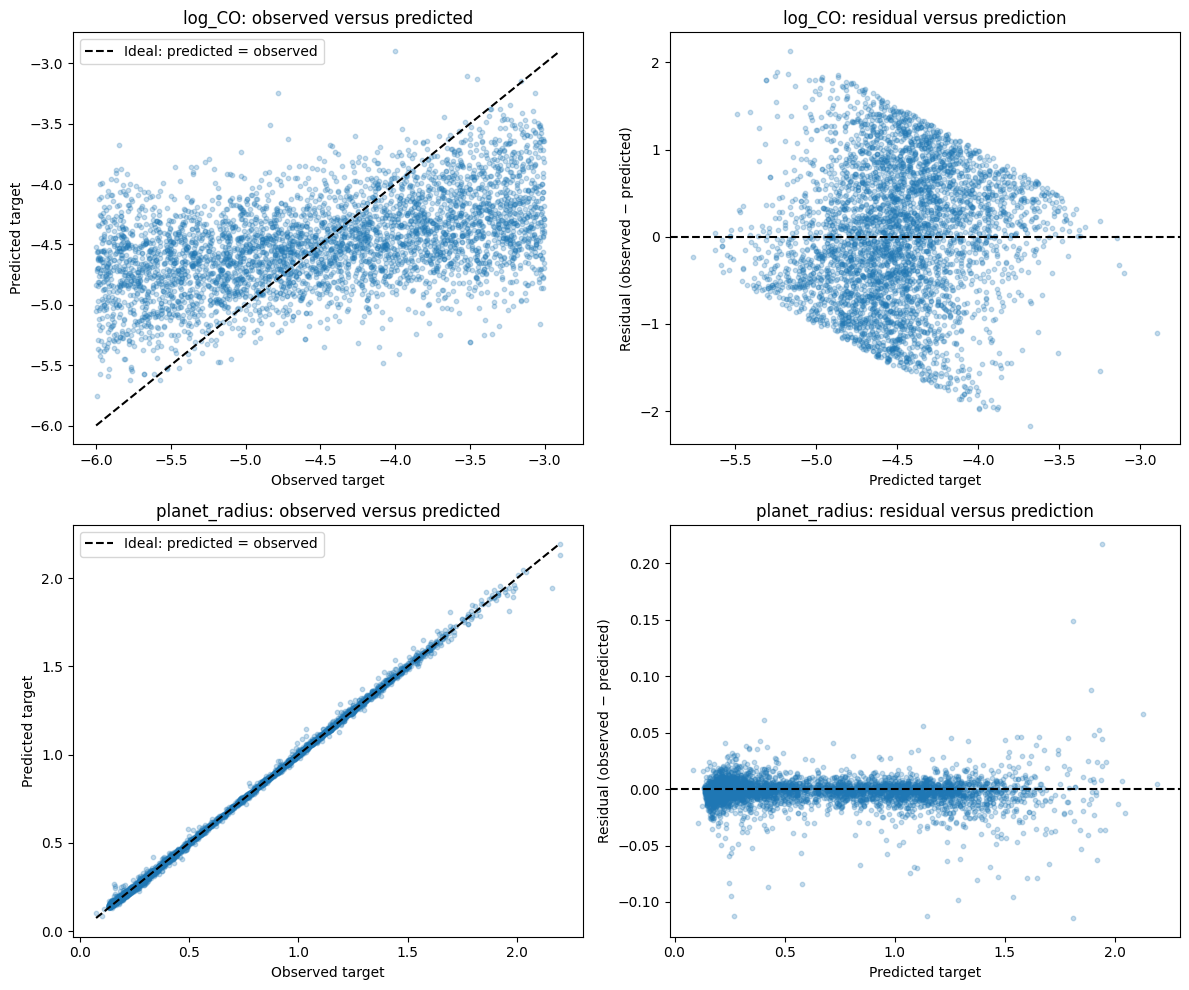

Displayed the targets with the lowest and highest selected-model validation R^2.


In [19]:
diagnostic_ranking = (validation_residuals_summary.sort_values("selected_validation_R2", kind="stable"))

diagnostic_targets = list(
    dict.fromkeys(
        [
            diagnostic_ranking.iloc[0]["target"],
            diagnostic_ranking.iloc[-1]["target"]
        ]
    )
)

fig, axes = plt.subplots(
    nrows=len(diagnostic_targets),
    ncols=2,
    figsize=(12, 5 * len(diagnostic_targets)),
    squeeze=False
)

for row_index, target in enumerate(diagnostic_targets):
    observed = y_val[target].to_numpy(dtype=np.float64)

    predicted = selected_validation_predictions[target]

    residual = observed - predicted

    observed_axis = axes[row_index, 0]
    residual_axis = axes[row_index, 1]

    observed_axis.scatter(
        observed,
        predicted,
        s=10,
        alpha=0.25,
        rasterized=True
    )

    common_minimum = min(observed.min(),predicted.min())

    common_maximum = max(observed.max(),predicted.max())

    observed_axis.plot(
        [common_minimum, common_maximum],
        [common_minimum, common_maximum],
        linestyle="--",
        color="black",
        label="Ideal: predicted = observed"
    )

    observed_axis.set_title(f"{target}: observed versus predicted")
    observed_axis.set_xlabel("Observed target")
    observed_axis.set_ylabel("Predicted target")
    observed_axis.legend()

    residual_axis.scatter(
        predicted,
        residual,
        s=10,
        alpha=0.25,
        rasterized=True
    )

    residual_axis.axhline(
        0.0,
        linestyle="--",
        color="black"
    )

    residual_axis.set_title(f"{target}: residual versus prediction")
    residual_axis.set_xlabel("Predicted target")
    residual_axis.set_ylabel("Residual (observed − predicted)")

plt.tight_layout()
plt.show()

print("Displayed the targets with the lowest and highest selected-model validation R^2.")

### **Residual diagnostics**

For `planet_radius`, the predicted values closely match the actual values, with most points lying near the diagonal line representing perfect predictions. The residuals are generally small, although a few larger errors occur, particularly for planets with larger predicted radii.

For `log_CO`, predictions are concentrated within a narrow range despite the actual values vary quite widely. This indicates that the model struggles to distinguish between planets with different CO abundances, consistent with it's low $R^2$.

In [20]:
from joblib import dump

SAVE_SELECTED_MODELS = True

CHECKPOINT_DIRECTORY = (
    PROJECT_ROOT / "checkpoints" / "predictive_baselines"
)

if SAVE_SELECTED_MODELS:
    CHECKPOINT_DIRECTORY.mkdir(parents=True, exist_ok=True)

    for target in TARGET_COLUMNS:
        family = selected_point_models[target]["family"]

        if family == "PyTorchNN":
            target_scaler = best_nn_target_scalers[target]

            checkpoint = {
                "target": target,
                "configuration": selected_point_models[target].copy(),
                "feature_columns": FEATURE_COLUMNS.copy(),
                "state_dict": {
                    name: value.detach().cpu().clone()
                    for name, value in selected_model_objects[target].state_dict().items()
                },
                "feature_scaler_mean": torch.from_numpy(NN_scaler.mean_.copy()),
                "feature_scaler_scale": torch.from_numpy(NN_scaler.scale_.copy()),
                "target_scaler_mean": torch.from_numpy(target_scaler.mean_.copy()),
                "target_scaler_scale": torch.from_numpy(target_scaler.scale_.copy())
            }

            checkpoint_path = (
                CHECKPOINT_DIRECTORY / f"{target}_selected_nn.pt"
            )

            torch.save(checkpoint, checkpoint_path)

        elif family == "HistGradientBoosting":
            checkpoint_path = (
                CHECKPOINT_DIRECTORY / f"{target}_selected_hgb.joblib"
            )

            dump(selected_model_objects[target], checkpoint_path)

        print("Saved:", checkpoint_path)

else:
    print("No selected models were saved.")

Saved: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction/checkpoints/predictive_baselines/planet_radius_selected_nn.pt
Saved: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction/checkpoints/predictive_baselines/planet_temp_selected_hgb.joblib
Saved: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction/checkpoints/predictive_baselines/log_H2O_selected_nn.pt
Saved: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction/checkpoints/predictive_baselines/log_CO2_selected_nn.pt
Saved: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction/checkpoints/predictive_baselines/log_CO_selected_hgb.joblib
Saved: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conformal-prediction/checkpoints/predictive_baselines/log_CH4_selected_nn.pt
Saved: /home/ajf23/Documents/Coding new/University stuff/ADC2023/ADC2023-conforma